# Part 3 — World Bank commodity prices + FRED market indicators
**Price-only versus price + FRED regime detection and portfolio allocation**

This standalone notebook extends Parts 1–2 using actual FRED observations included in `data/raw/fred`. No internet or API key is required. News sentiment is excluded.

We compare six strategies on identical dates: equal weight, unconditional Markowitz, K-Means and GMM with commodity-price features, and K-Means and GMM with price + FRED features. The five risky assets remain Brent, US natural gas, gold, silver and copper. The indicators are predictors, not portfolio assets.

**Status:** illustrative monthly-average price-proxy study, not an investable futures/ETF backtest. It retains the World Bank publication/vintage and execution limitations discussed in Part 2. FRED snapshots may also be revised. The final test has previously been inspected; this extension is exploratory and not a new untouched confirmation.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
BASE=Path.cwd()
if not (BASE/'data').exists(): BASE=BASE/'commodity_regimes'
OUT=BASE/'results/fred_extension'; OUT.mkdir(parents=True,exist_ok=True)
SEED=42
plt.rcParams.update({'figure.figsize':(11,4),'axes.grid':True,'grid.alpha':.2})
def plot_save(name):
    plt.tight_layout(); plt.savefig(OUT/name,dpi=150,bbox_inches='tight'); plt.show()
prices=pd.read_csv(BASE/'data/processed/prices_2000_2025.csv',index_col='date',parse_dates=True)
ret=prices.pct_change(fill_method=None).dropna()
lr=np.log(prices).diff().dropna()
X=pd.concat({'r1':lr,'mom3':lr.rolling(3).sum(),
             'vol12':lr.rolling(12).std()*np.sqrt(12)},axis=1).dropna()
X.columns=['__'.join(c) for c in X.columns]
print('Data:',prices.shape,'| Features:',X.shape)

Data: (312, 5) | Features: (300, 15)


## 1. Actual FRED sources and monthly aggregation
| ID | Indicator | Native units | Role |
|---|---|---|---|
| VIXCLS | CBOE VIX | Index | Equity-market implied volatility, a broad risk indicator |
| DTWEXBGS | Nominal broad US dollar | Jan 2006=100 | Dollar movements |
| DGS10 | 10-year Treasury yield | Percent | Long-rate level and changes |
| DGS2 | 2-year Treasury yield | Percent | Yield-curve slope with DGS10 |

Source pages: https://fred.stlouisfed.org/series/VIXCLS ; https://fred.stlouisfed.org/series/DTWEXBGS ; https://fred.stlouisfed.org/series/DGS10 ; https://fred.stlouisfed.org/series/DGS2 . Downloads use FRED's CSV export; source identifiers and raw files are preserved. Original providers are CBOE for VIX and the Federal Reserve Board for the dollar and yields. See each source's usage notes.

For each calendar month, take the mean of available daily observations. Blank holidays are not treated as zeros and are not forward-filled. Require at least ten valid observations per series/month. The broad dollar series starts in 2006, shortening the common feature history. We do not splice in a different index to create artificial earlier observations.

,series_id,first_valid_daily,last_valid_daily
0,VIXCLS,1999-01-04,2025-12-31
1,DTWEXBGS,2006-01-02,2025-12-31
2,DGS10,1999-01-04,2025-12-31
3,DGS2,1999-01-04,2025-12-31


,VIXCLS,DTWEXBGS,DGS10,DGS2
observation_date,,,,
2006-01-01,12.036000,100.000005,4.416000,4.395500
2006-02-01,12.471053,100.211170,4.568947,4.668421
2006-03-01,11.693913,100.428087,4.723913,4.733913
2006-04-01,11.847368,99.743480,4.990526,4.888947
2006-05-01,14.454545,97.511774,5.110000,4.968182


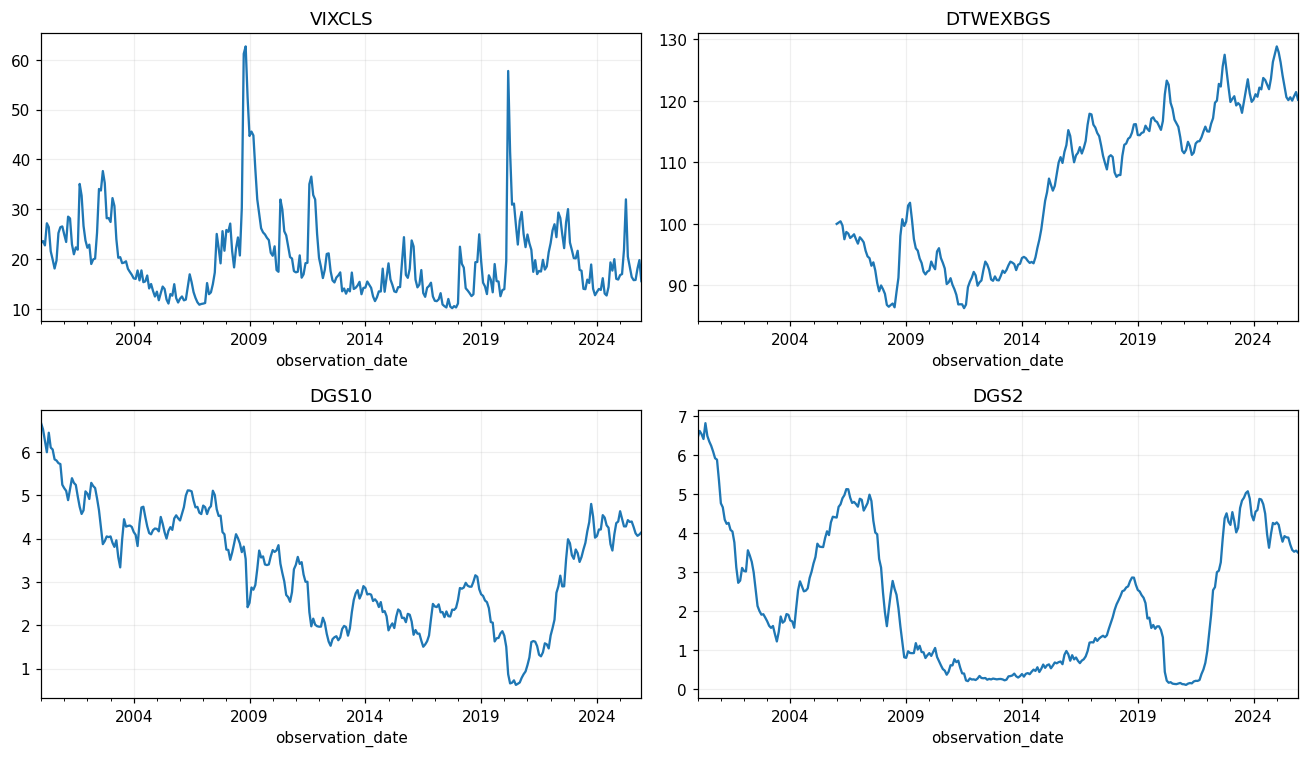

In [2]:
IDS=['VIXCLS','DTWEXBGS','DGS10','DGS2']
monthly={};counts={};manifest=[]
for sid in IDS:
    path=BASE/'data/raw/fred'/f'{sid}.csv'
    daily=pd.read_csv(path,index_col=0,parse_dates=True)
    values=pd.to_numeric(daily[sid],errors='coerce').sort_index()
    assert values.index.is_unique
    cnt=values.resample('MS').count()
    monthly[sid]=values.resample('MS').mean().where(cnt>=10)
    counts[sid]=cnt
    manifest.append({'series_id':sid,'source_page':f'https://fred.stlouisfed.org/series/{sid}',
      'download_url':f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}&cosd=1999-01-01&coed=2025-12-31',
      'retrieved_on':'2026-11-07','sha256':__import__('hashlib').sha256(path.read_bytes()).hexdigest(),
      'first_valid_daily':str(values.first_valid_index().date()),
      'last_valid_daily':str(values.last_valid_index().date())})
fred=pd.DataFrame(monthly).loc['2000':'2025']
fred_counts=pd.DataFrame(counts).reindex(fred.index)
fred.to_csv(BASE/'data/processed/fred_monthly.csv')
fred_counts.to_csv(BASE/'data/processed/fred_monthly_valid_day_counts.csv')
(BASE/'data/fred_sources.json').write_text(json.dumps(manifest,indent=2))
display(pd.DataFrame(manifest)[['series_id','first_valid_daily','last_valid_daily']])
display(fred.dropna().head())
fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,sid in zip(axes.flat,IDS):fred[sid].plot(ax=ax,title=sid)
plot_save('01_fred_series.png')

## 2. Feature definitions and common sample
Commodity features are unchanged: five monthly log changes, five three-month momenta, five twelve-month volatilities (15 variables).

Add six FRED features: log VIX level; one- and three-month dollar log changes; 10-year yield level; one-month 10-year yield change; and 10y–2y yield slope. Yield changes and slopes are in percentage points, not decimal returns. Standardization is learned only on training observations.

This is a compact economic specification, fixed without optimizing test portfolio results. The price block has 15 dimensions versus six FRED dimensions; we use ordinary per-variable standardization without additional block reweighting. It is a starting specification, not a guarantee of balanced economic influence.

In [3]:
price_features=X.copy()
macro=pd.DataFrame({
 'fred_log_vix':np.log(fred.VIXCLS),
 'fred_dollar_return_1m':np.log(fred.DTWEXBGS).diff(),
 'fred_dollar_momentum_3m':np.log(fred.DTWEXBGS).diff(3),
 'fred_yield10_level_pp':fred.DGS10,
 'fred_yield10_change_1m_pp':fred.DGS10.diff(),
 'fred_yield_slope_10y2y_pp':fred.DGS10-fred.DGS2})
combined=price_features.join(macro).replace([np.inf,-np.inf],np.nan).dropna()
common=combined.index
price_features=price_features.loc[common]
assert len(combined.columns)==21 and combined.index.equals(price_features.index)
assert combined.index.equals(pd.date_range(common.min(),common.max(),freq='MS'))
combined.to_csv(BASE/'data/processed/features_worldbank_fred.csv')
price_features.to_csv(BASE/'data/processed/features_price_only_common_sample.csv')
feature_sets={'price':price_features,'price_fred':combined}
print('Common sample:',common.min().date(),'to',common.max().date(),len(common),'months')
display(pd.DataFrame({'features':[15,21]},index=['price','price_fred']))

Common sample: 2006-04-01 to 2025-12-01 237 months


,features
price,15
price_fred,21


## 3. Select cluster counts before the test
Both feature sets use the same train dates (common start–2015), validation (2016–2020), and held-out portfolio outcomes (March 2021–December 2025). K-Means selects 2–4 groups by validation silhouette; GMM selects 2–4 diagonal-covariance components by training BIC.

Refit on the common history through December 2020, then freeze the scaler and clustering model throughout the test. Re-selecting cluster counts on the reduced common sample makes the comparison methodologically symmetric. The historical price-only results in Part 2 remain as an archive, but the **paired comparison here** uses price-only models refitted on this same reduced sample.

In [4]:
from sklearn.metrics import silhouette_score,adjusted_rand_score
MODEL_END=pd.Timestamp('2020-12-01')
model_store={};selection_rows=[];probabilities={};label_table=pd.DataFrame(index=common)
for feature_name,data in feature_sets.items():
    train=data.loc[:'2015'];valid=data.loc['2016':'2020'];dev=data.loc[:MODEL_END]
    scale=StandardScaler().fit(train)
    zt=scale.transform(train);zv=scale.transform(valid)
    scores=[];bics=[]
    for k in [2,3,4]:
        a=KMeans(n_clusters=k,n_init=30,random_state=SEED).fit(zt)
        v=a.predict(zv)
        sil=silhouette_score(zv,v) if 1<len(np.unique(v))<len(v) else np.nan
        b=GaussianMixture(n_components=k,covariance_type='diag',reg_covar=1e-4,
            n_init=10,max_iter=500,random_state=SEED).fit(zt)
        scores.append(sil);bics.append(b.bic(zt))
        selection_rows.append({'features':feature_name,'k':k,'validation_silhouette':sil,
           'train_gmm_BIC':b.bic(zt),'train_months':len(train),'validation_months':len(valid)})
    assert np.isfinite(scores).any()
    nk=int(np.array([2,3,4])[np.nanargmax(scores)])
    ng=int(np.array([2,3,4])[np.argmin(bics)])
    fs=StandardScaler().fit(dev);zd=fs.transform(dev);za=fs.transform(data)
    a=KMeans(n_clusters=nk,n_init=50,random_state=SEED).fit(zd)
    b=GaussianMixture(n_components=ng,covariance_type='diag',reg_covar=1e-4,
       n_init=20,max_iter=500,random_state=SEED).fit(zd)
    assert b.converged_
    for alg,model in [('KMeans',a),('GMM',b)]:
        key=f'{alg} {feature_name}'
        y=model.predict(za);label_table[key]=y
        pp=np.eye(nk)[y] if alg=='KMeans' else model.predict_proba(za)
        probabilities[key]=pd.DataFrame(pp,index=common)
        model_store[key]={'scaler':fs,'model':model,'Z':za,'columns':data.columns}
selection=pd.DataFrame(selection_rows)
display(selection.round(4))
selection.to_csv(OUT/'model_selection.csv',index=False)
label_table.to_csv(OUT/'regime_labels_common_sample.csv')
print('Selected counts:',{name:p.shape[1] for name,p in probabilities.items()})

Selected counts: {'KMeans price': 3, 'GMM price': 4, 'KMeans price_fred': 4, 'GMM price_fred': 4}


,features,k,validation_silhouette,train_gmm_BIC,train_months,validation_months
0,price,2,0.1537,4808.6911,117,60
1,price,3,0.2859,4591.0125,117,60
2,price,4,0.1445,4590.4906,117,60
3,price_fred,2,0.1589,6759.2377,117,60
4,price_fred,3,0.2194,6407.4500,117,60
5,price_fred,4,0.2536,6231.1089,117,60


## 4. Regime interpretation and held-out occupancy
Describe the states using development data only: mean commodity movement, trailing commodity volatility, VIX, dollar movement and yield slope. State numbers are arbitrary across models. Held-out occupancy reveals small groups; a rarely observed group does not support precise performance inference.

,regime,commodity_log_change,commodity_vol12,vix,dollar_log_change,yield_slope_pp,development_months,model
0,0,-0.119,0.326,36.505,0.022,1.189,11,KMeans price
1,1,-0.004,0.231,16.742,0.003,1.293,121,KMeans price
2,2,0.045,0.318,23.186,-0.010,1.342,45,KMeans price
3,0,-0.038,0.371,24.296,0.008,0.602,17,GMM price
4,1,0.041,0.394,29.721,-0.011,1.550,16,GMM price
5,2,-0.015,0.212,16.346,0.005,1.084,73,GMM price
6,3,0.019,0.250,19.561,-0.003,1.631,71,GMM price
7,0,-0.078,0.276,33.630,0.022,1.564,18,KMeans price_fred
8,1,0.045,0.311,24.528,-0.010,1.683,42,KMeans price_fred
9,2,-0.002,0.353,14.114,-0.003,-0.001,15,KMeans price_fred


,regime,test_months,model
0,1,46,KMeans price
1,2,11,KMeans price
2,0,1,KMeans price
3,3,44,GMM price
4,2,14,GMM price
5,3,29,KMeans price_fred
6,2,20,KMeans price_fred
7,1,8,KMeans price_fred
8,0,1,KMeans price_fred
9,0,32,GMM price_fred


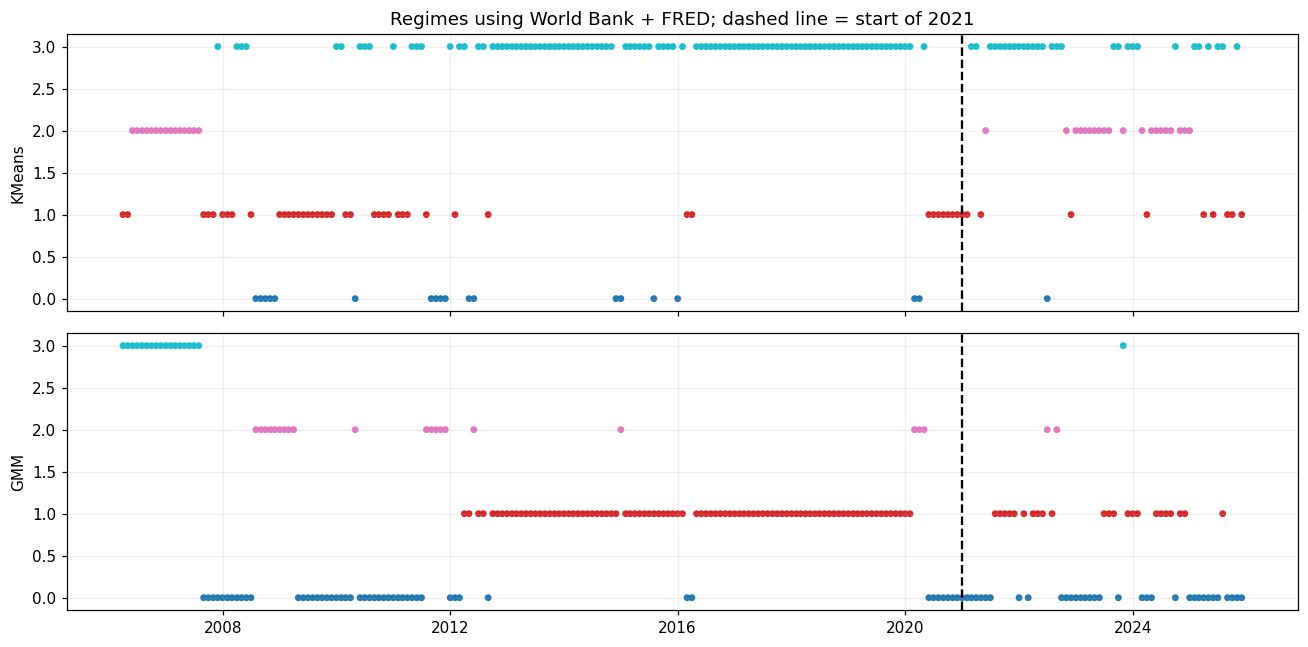

In [5]:
profiles=pd.DataFrame({'commodity_log_change':lr.mean(axis=1),
 'commodity_vol12':price_features.filter(like='vol12__').mean(axis=1),
 'vix':fred.VIXCLS,'dollar_log_change':macro.fred_dollar_return_1m,
 'yield_slope_pp':macro.fred_yield_slope_10y2y_pp}).reindex(common)
profile_tables=[];occupancies=[]
for name in probabilities:
    table=profiles.loc[:MODEL_END].join(label_table[name].rename('regime')).groupby('regime').mean()
    table['development_months']=label_table.loc[:MODEL_END,name].value_counts()
    table['model']=name;profile_tables.append(table.reset_index())
    occ=label_table.loc['2021-03':'2025-12',name].value_counts().rename_axis('regime').reset_index(name='test_months')
    occ['model']=name;occupancies.append(occ)
profile_tables=pd.concat(profile_tables,ignore_index=True)
occupancies=pd.concat(occupancies,ignore_index=True)
display(profile_tables.round(3));display(occupancies)
profile_tables.to_csv(OUT/'development_regime_profiles.csv',index=False)
occupancies.to_csv(OUT/'test_regime_occupancy.csv',index=False)
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True)
for ax,alg in zip(axes,['KMeans','GMM']):
    lab=label_table[f'{alg} price_fred']
    ax.scatter(lab.index,lab,c=lab,cmap='tab10',s=12)
    ax.axvline(pd.Timestamp('2021-01-01'),color='black',ls='--')
    ax.set_ylabel(alg)
axes[0].set_title('Regimes using World Bank + FRED; dashed line = start of 2021')
plot_save('02_fred_regimes.png')

## 5. Identical portfolio rules for the paired comparison
The objective is $\max_w w^T\hat\mu-\gamma w^T\hat\Sigma w/2$, with $\gamma=5$, full investment, long-only positions and a 60% asset cap. Estimate moments on the trailing 120 monthly commodity-price changes ending at the two-month signal cutoff. Means shrink 50% to zero; covariances shrink 20% to their diagonal.

Conditional historical pairs link state at $s$ to return at $s+2$. Blend state-conditioned moments toward unconditional moments with effective-sample strength $n/(n+24)$; below 12 effective observations fall back to unconditional moments. GMM uses soft membership and a covariance mixture including between-component mean dispersion.

Only clustering inputs differ between the price-only and price+FRED variants. All strategies have identical traded assets, estimation windows, signal lags, risk aversion, constraints, costs and evaluation dates. FRED does not change the unconditional Markowitz benchmark or the risk-free-rate convention (Sharpe uses rf=0).

In [6]:
LOOKBACK=120; GAMMA=5.0; CAP=.60; COV_SHRINK=.20; MEAN_SHRINK=.50
PRIOR=24; MIN_EFFECTIVE=12; LAG=2; FEE_BPS=10
test_dates=ret.loc['2021-03':'2025-12'].index
assert len(test_dates)==58
def raw_moments(values, weights=None):
    a=np.asarray(values,dtype=float)
    p=np.ones(len(a)) if weights is None else np.asarray(weights,dtype=float)
    p=p/p.sum()
    mu=p@a; centered=a-mu
    cov=(centered*p[:,None]).T@centered
    return mu,cov

def regularize(mu,cov):
    cov=(1-COV_SHRINK)*cov+COV_SHRINK*np.diag(np.diag(cov))
    cov=(cov+cov.T)/2+np.eye(len(mu))*1e-8
    return (1-MEAN_SHRINK)*mu,cov

def optimize(mu,cov,gamma=GAMMA):
    n=len(mu)
    objective=lambda w: gamma/2*(w@cov@w)-w@mu
    gradient=lambda w: gamma*(cov@w)-mu
    result=minimize(objective,np.repeat(1/n,n),jac=gradient,method='SLSQP',
        bounds=[(0,CAP)]*n,constraints={'type':'eq','fun':lambda w:w.sum()-1,
        'jac':lambda w:np.ones(n)},options={'ftol':1e-12,'maxiter':500})
    if not result.success: raise RuntimeError(result.message)
    w=result.x
    assert abs(w.sum()-1)<1e-8 and w.min()>-1e-8 and w.max()<CAP+1e-8
    return w
def blend_moments(mu_a,cov_a,mu_b,cov_b,alpha):
    mu=alpha*mu_a+(1-alpha)*mu_b
    second=alpha*(cov_a+np.outer(mu_a,mu_a))+(1-alpha)*(cov_b+np.outer(mu_b,mu_b))
    return mu,second-np.outer(mu,mu)

def conditional_moments(history,probabilities,cutoff):
    # Outcome u is paired with signal u-2; align by actual calendar month.
    signals=history.index-pd.DateOffset(months=LAG)
    ok=signals.isin(probabilities.index)
    outcomes=history.loc[ok]
    signals=signals[ok]
    prior_mu,prior_cov=raw_moments(history)
    historical_p=probabilities.loc[signals].to_numpy()
    current_p=probabilities.loc[cutoff].to_numpy()
    component_mu=[]; component_cov=[]; effective=[]; fallback=0
    for j in range(historical_p.shape[1]):
        a=historical_p[:,j]; mass=a.sum()
        neff=mass*mass/(a@a) if a@a>0 else 0.0
        effective.append(neff)
        if neff<MIN_EFFECTIVE:
            mu,cov=prior_mu,prior_cov; fallback+=1
        else:
            cm,cc=raw_moments(outcomes,a)
            mu,cov=blend_moments(cm,cc,prior_mu,prior_cov,neff/(neff+PRIOR))
        component_mu.append(mu);component_cov.append(cov)
    means=np.array(component_mu)
    mu=current_p@means
    second=sum(p*(c+np.outer(m,m)) for p,m,c in zip(current_p,means,component_cov))
    cov=second-np.outer(mu,mu)
    return mu,cov,{'effective_current':float(current_p@np.array(effective)),
                  'fallback_components':fallback,'latest_outcome':history.index.max()}

In [7]:
NAMES=['Equal weight','Markowitz']+list(probabilities)
weights={name:[] for name in NAMES};audit=[]
for date in test_dates:
    cutoff=date-pd.DateOffset(months=LAG)
    assert cutoff>MODEL_END and cutoff<date
    history=ret.loc[:cutoff].tail(LOOKBACK)
    assert len(history)==LOOKBACK and history.index.max()==cutoff
    weights['Equal weight'].append(np.repeat(1/ret.shape[1],ret.shape[1]))
    weights['Markowitz'].append(optimize(*regularize(*raw_moments(history))))
    for name,prob in probabilities.items():
        mu,cov,info=conditional_moments(history,prob,cutoff)
        weights[name].append(optimize(*regularize(mu,cov)))
        audit.append({'outcome_month':date,'signal_cutoff':cutoff,'model':name,**info})
weights={name:pd.DataFrame(a,index=test_dates,columns=ret.columns) for name,a in weights.items()}
audit=pd.DataFrame(audit);audit.to_csv(OUT/'timing_audit.csv',index=False)
for name,w in weights.items():
    assert np.allclose(w.sum(axis=1),1) and w.min().min()>-1e-8 and w.max().max()<=CAP+1e-8
    w.to_csv(OUT/(name.replace(' ','_')+'_weights.csv'))
print('Common test months:',len(test_dates))
display(audit.head())

Common test months: 58


,outcome_month,signal_cutoff,model,effective_current,fallback_components,latest_outcome
0,2021-03-01,2021-01-01,KMeans price,15.000000,1,2021-01-01
1,2021-03-01,2021-01-01,GMM price,6.000418,2,2021-01-01
2,2021-03-01,2021-01-01,KMeans price_fred,15.000000,1,2021-01-01
3,2021-03-01,2021-01-01,GMM price_fred,21.356449,2,2021-01-01
4,2021-04-01,2021-02-01,KMeans price,15.000000,1,2021-02-01


## 6. Backtest and results
Rebalance monthly. Pretrade holdings drift with the previous month's asset changes. Turnover is the sum of absolute traded weights (not divided by two); the initial move from cash has turnover 1. Pay 10 bp per traded dollar before the proxy return: $(1-cost)(1+w^Tr)-1$.

CAGR uses net compounding; volatility and rf=0 Sharpe use monthly observations annualized by 12. Drawdown includes initial wealth 1. These are synthetic price-proxy metrics.

In [8]:
def backtest(weight_table,fee_bps):
    pretrade=np.zeros(ret.shape[1]); rows=[]
    for date,wrow in weight_table.iterrows():
        w=wrow.to_numpy(); r=ret.loc[date].to_numpy()
        turnover=np.abs(w-pretrade).sum()
        gross=float(w@r);cost=fee_bps/10000*turnover
        net=(1-cost)*(1+gross)-1
        rows.append([gross,net,turnover,cost])
        pretrade=w*(1+r)/(1+gross)
    return pd.DataFrame(rows,index=weight_table.index,
                        columns=['gross_return','net_return','turnover','cost_fraction'])
paths={name:backtest(w,FEE_BPS) for name,w in weights.items()}
net=pd.DataFrame({name:p.net_return for name,p in paths.items()})
gross=pd.DataFrame({name:p.gross_return for name,p in paths.items()})
wealth=(1+net).cumprod()
# Include initial wealth=1 when calculating drawdowns.
initial=test_dates[0]-pd.DateOffset(months=1)
wealth_with_start=pd.concat([pd.DataFrame(1.,index=[initial],columns=NAMES),wealth])
drawdown=wealth_with_start/wealth_with_start.cummax()-1
net.to_csv(OUT/'monthly_net_proxy_returns.csv')
gross.to_csv(OUT/'monthly_gross_proxy_returns.csv')
wealth.to_csv(OUT/'wealth_indices.csv')
for name,p in paths.items():p.to_csv(OUT/(name.lower().replace(' ','_')+'_backtest.csv'))

,CAGR,annualized_vol,Sharpe_rf0,max_drawdown,mean_monthly_turnover,positive_month_fraction,total_return
Equal weight,0.1296,0.1736,0.7915,-0.2533,0.0732,0.6207,0.8024
Markowitz,0.1369,0.1187,1.1448,-0.1707,0.0612,0.6552,0.8591
KMeans price,0.1329,0.1289,1.0361,-0.1655,0.1633,0.6207,0.8278
GMM price,0.1452,0.1308,1.1067,-0.1938,0.1872,0.6897,0.9258
KMeans price_fred,0.1337,0.1291,1.0406,-0.1660,0.1886,0.6552,0.8340
GMM price_fred,0.1079,0.1255,0.8821,-0.1910,0.1734,0.6379,0.6410


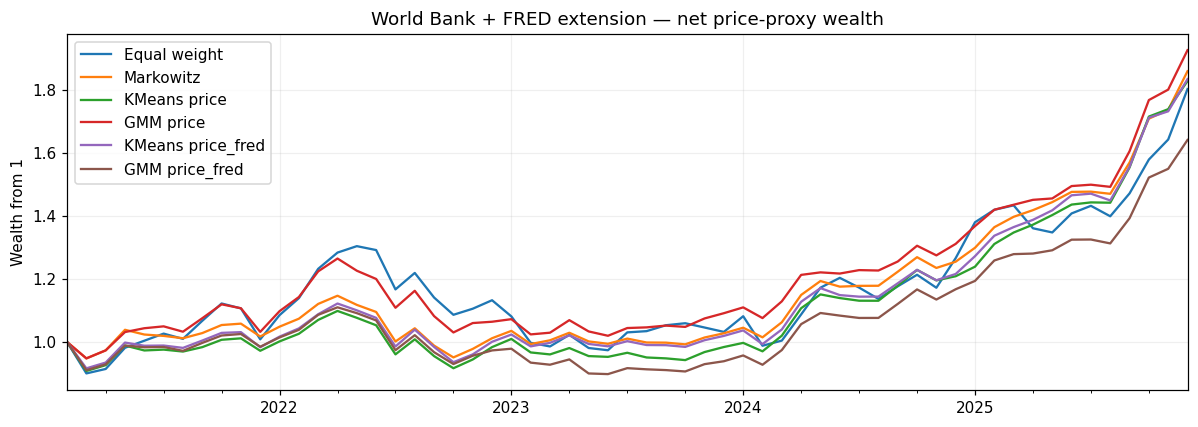

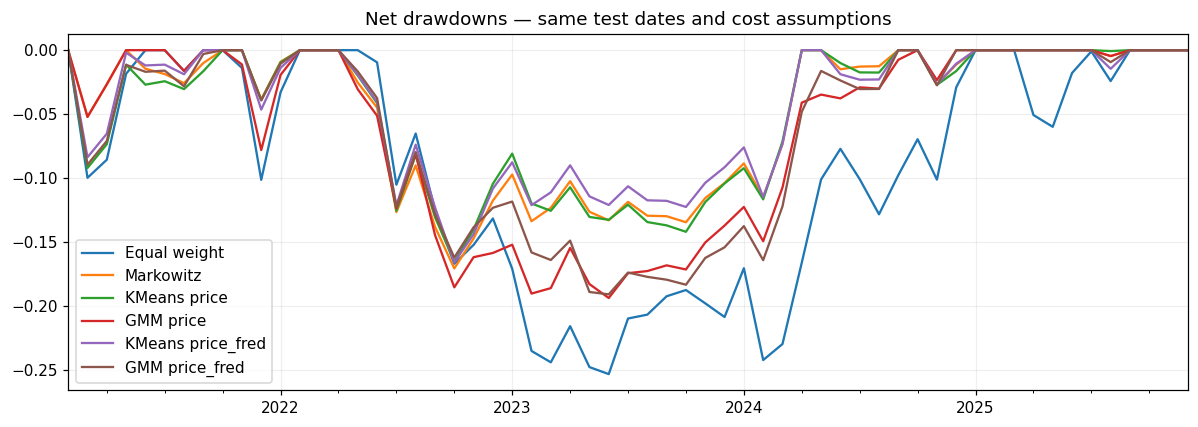

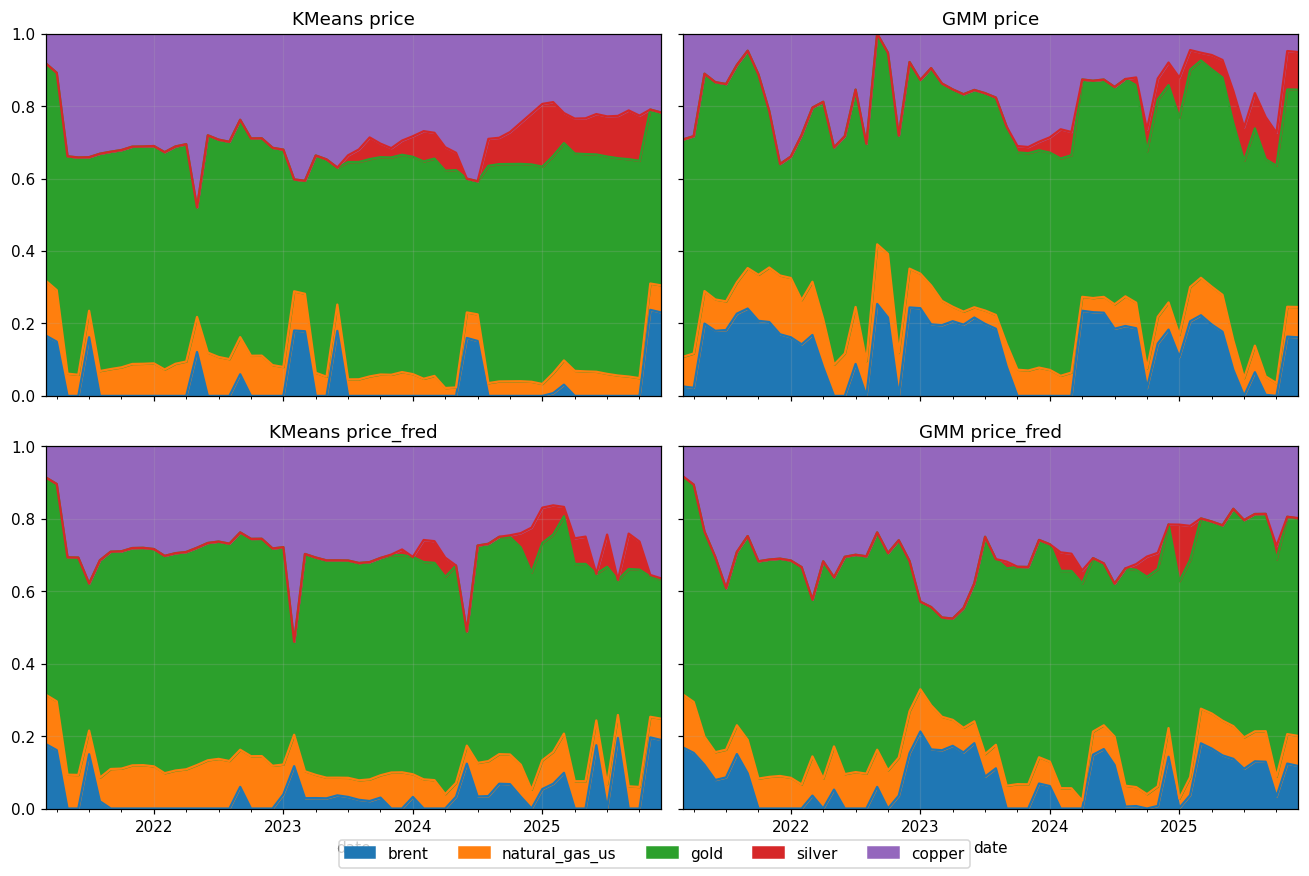

In [9]:
def metrics(returns,turnover):
    vol=returns.std(ddof=1)*np.sqrt(12)
    curve=pd.concat([pd.Series([1.]),(1+returns).cumprod().reset_index(drop=True)],ignore_index=True)
    dd=curve/curve.cummax()-1
    return pd.Series({'CAGR':(1+returns).prod()**(12/len(returns))-1,
        'annualized_vol':vol,'Sharpe_rf0':returns.mean()*12/vol if vol>0 else np.nan,
        'max_drawdown':dd.min(),'mean_monthly_turnover':turnover.mean(),
        'positive_month_fraction':returns.gt(0).mean(),'total_return':(1+returns).prod()-1})

summary=pd.DataFrame({name:metrics(net[name],paths[name].turnover) for name in NAMES}).T
summary.to_csv(OUT/'performance_summary.csv')
display(summary.round(4))
wealth_with_start.plot(title='World Bank + FRED extension — net price-proxy wealth')
plt.ylabel('Wealth from 1');plot_save('03_portfolio_comparison.png')
drawdown.plot(title='Net drawdowns — same test dates and cost assumptions')
plot_save('04_drawdowns.png')
fig,axes=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
for ax,name in zip(axes.flat,list(probabilities)):
    weights[name].plot.area(ax=ax,ylim=(0,1),title=name,legend=False)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',ncol=5)
plot_save('05_conditional_weights.png')

## 7. Incremental FRED effect, uncertainty and costs
Compare each algorithm with itself on the same sample: price+FRED minus price-only. A paired six-month circular block bootstrap jointly resamples portfolio returns (1,000 replications) for a rough interval on the Sharpe difference. It does not refit models or correct for the exploratory research process. Intervals containing zero do not support a clear positive difference in this diagnostic.

The previously viewed test period is not an independent holdout for this new specification. Report this comparison as exploratory and validate any further conclusions on new dates or a predeclared walk-forward evaluation.

In [10]:
rng=np.random.default_rng(SEED);n=len(net);B=1000;block=6
pairs=[('KMeans price_fred','KMeans price'),('GMM price_fred','GMM price'),
       ('KMeans price_fred','Markowitz'),('GMM price_fred','Markowitz')]
boot={f'{a} minus {b}':[] for a,b in pairs}
for _ in range(B):
    starts=rng.integers(0,n,size=int(np.ceil(n/block)))
    ix=np.concatenate([(s+np.arange(block))%n for s in starts])[:n]
    sample=net.iloc[ix]
    sr=sample.mean()/sample.std(ddof=1)*np.sqrt(12)
    for a,b in pairs:boot[f'{a} minus {b}'].append(sr[a]-sr[b])
diffs=[]
for a,b in pairs:
    key=f'{a} minus {b}'
    diffs.append({'comparison':key,'Sharpe_difference':summary.loc[a,'Sharpe_rf0']-summary.loc[b,'Sharpe_rf0'],
       'bootstrap_low':np.quantile(boot[key],.025),'bootstrap_high':np.quantile(boot[key],.975)})
diffs=pd.DataFrame(diffs);display(diffs.round(4));diffs.to_csv(OUT/'paired_comparisons.csv',index=False)
sensitivity=[]
for fee in [0,10,25]:
    for name,w in weights.items():
        bt=backtest(w,fee)
        sensitivity.append({'strategy':name,'fee_bps':fee,**metrics(bt.net_return,bt.turnover).to_dict()})
sensitivity=pd.DataFrame(sensitivity)
sensitivity.to_csv(OUT/'cost_sensitivity.csv',index=False)
display(sensitivity.pivot(index='strategy',columns='fee_bps',values='Sharpe_rf0').round(3))
for name in NAMES:
    assert np.isfinite(net[name]).all() and net[name].index.equals(test_dates)
    assert (net[name]<=gross[name]+1e-12).all()
    assert abs(paths[name].turnover.iloc[0]-1)<1e-8
    assert np.allclose(backtest(weights[name],0).net_return,gross[name])
    assert (backtest(weights[name],25).net_return<=net[name]+1e-12).all()
assert audit.latest_outcome.eq(audit.signal_cutoff).all()
print('Checks passed: common dates, actual data, constraints, finite returns, publication lags and cost accounting.')

Checks passed: common dates, actual data, constraints, finite returns, publication lags and cost accounting.


,comparison,Sharpe_difference,bootstrap_low,bootstrap_high
0,KMeans price_fred minus KMeans price,0.0045,-0.1799,0.1405
1,GMM price_fred minus GMM price,-0.2245,-0.5709,0.0836
2,KMeans price_fred minus Markowitz,-0.1042,-0.3675,0.0968
3,GMM price_fred minus Markowitz,-0.2626,-0.5842,0.0049


fee_bps,0,10,25
strategy,,,
Equal weight,0.797,0.792,0.783
GMM price,1.125,1.107,1.080
GMM price_fred,0.899,0.882,0.857
KMeans price,1.053,1.036,1.010
KMeans price_fred,1.059,1.041,1.012
Markowitz,1.152,1.145,1.134


## Observed results from this execution

| Strategy | CAGR | Volatility | Sharpe rf=0 | Max drawdown |
|---|---:|---:|---:|---:|
| Equal weight | 12.96% | 17.36% | 0.79 | -25.33% |
| Markowitz | 13.69% | 11.87% | 1.14 | -17.07% |
| KMeans price | 13.29% | 12.89% | 1.04 | -16.55% |
| GMM price | 14.52% | 13.08% | 1.11 | -19.38% |
| KMeans price_fred | 13.37% | 12.91% | 1.04 | -16.60% |
| GMM price_fred | 10.79% | 12.55% | 0.88 | -19.10% |

Incremental FRED effect relative to the same algorithm on commodity features only:

- KMeans price_fred minus KMeans price: Sharpe difference +0.004; approximate paired interval [-0.180, 0.141].
- GMM price_fred minus GMM price: Sharpe difference -0.225; approximate paired interval [-0.571, 0.084].

A change in ranking is a result of this exploratory specification, not proof that FRED indicators improve future investable performance. The original two notebooks are retained; use this third notebook for the fair common-sample comparison.